# Bildverarbeitung Belegarbeit 2

Willkommen zu dieser praktischen Übung zur Bildverarbeitung! In diesem Notebook werden wir uns mit fundamentalen Techniken zur Bildfilterung, Segmentierung und Merkmalsextraktion beschäftigen.

Das Ziel bleibt dasselbe: Wir werden diese Methoden **von Grund auf implementieren**, um ein tiefes Verständnis für die zugrunde liegenden Algorithmen und Operationen zu entwickeln, anstatt nur fertige Bibliotheksfunktionen zu verwenden.

Wir werden uns durch eine typische Pipeline der Bildanalyse arbeiten:

1.  **Filter-Operatoren**: Wir beginnen mit der Rauschunterdrückung und Bildverbesserung. Sie werden zwei essenzielle Filter implementieren:
    * Den **Median-Filter** als robusten, nicht-linearen Ansatz zur Entfernung von Ausreißern (z.B. Salz-und-Pfeffer-Rauschen).
    * Die **2D-Faltung (conv2d)** als Basis für lineare Filter (z.B. Glättung oder Kantenhervorhebung durch eigene Filterkerne).

2.  **Automatische Schwellenwertfindung (Thresholding)**: Um Bilder in Vorder- und Hintergrund zu trennen (Binarisierung), implementieren wir zwei klassische automatische Verfahren:
    * Einen **iterativen Algorithmus**, der den Schwellenwert schrittweise verfeinert, bis er konvergiert.
    * Die **Methode von Otsu**, ein statistischer Ansatz, der die Varianz zwischen den Klassen maximiert.

3.  **Morphologische Operatoren**: Aufbauend auf den binarisierten Bildern, werden wir die **Öffnung (Opening)** implementieren. Sie lernen, wie diese Operation (eine Kombination aus Erosion und Dilatation) genutzt wird, um Rauschen zu entfernen und die Konturen von Objekten zu glätten.

4.  **Hough-Transformation**: Zum Abschluss widmen wir uns der Merkmalsextraktion. Wir implementieren die Hough-Transformation, eine leistungsstarke Technik, um geometrische Formen – in unserem Fall **Linien** – in einem Bild zu detektieren, selbst wenn diese lückenhaft oder verrauscht sind.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

## Teil 1: Filter-Operatoren zur Rauschunterdrückung

In der realen Welt sind Bilder selten perfekt. Sie enthalten oft Rauschen, das durch den Aufnahmesensor, die Datenübertragung oder andere Störungen entsteht. Das Ziel der Bildfilterung ist es, dieses Rauschen zu unterdrücken und gleichzeitig wichtige Bildstrukturen (wie Kanten) so gut wie möglich zu erhalten.

In dieser ersten Aufgabe werden wir unsere Filter auf ein Bild anwenden, das mit **Salz-und-Pfeffer-Rauschen** (Salt-and-Pepper-Noise) versehen ist. Diese Rauschart zeichnet sich durch einzelne, zufällig verteilte Pixel aus, die entweder den maximalen (weiß, "Salz") oder den minimalen (schwarz, "Pfeffer") Helligkeitswert annehmen.

Wir werden zwei fundamentale Filtertypen von Grund auf implementieren, um dieses Rauschen zu bekämpfen: einen linearen und einen nicht-linearen Ansatz.

### Der 3x3 Box-Filter (Lineare Faltung)

Der **3x3 Box-Filter** (auch Mittelwertfilter genannt) ist ein klassischer linearer Glättungsfilter. Er ersetzt den Wert jedes Pixels durch den **Durchschnittswert** aller Pixel in seiner 3x3-Nachbarschaft (also das zentrale Pixel und seine 8 Nachbarn).

Dieser Vorgang wird formal durch eine Operation namens **Faltung (Convolution)** beschrieben. In vielen Implementierungen (und in unserer Übung) wird dabei die **Cross-Korrelation** berechnet, bei der der Filterkern (Kernel) *nicht* gespiegelt wird.

Für ein Ausgabebild $G$, ein Eingabebild $I$ und einen 3x3-Kern $K$ ist die Operation für ein Pixel an der Koordinate $(i, j)$ definiert als:

$$G(i, j) = \sum_{u=-1}^{1} \sum_{v=-1}^{1} K(u, v) \cdot I(i+u, j+v)$$

Für unseren 3x3 Box-Filter ist der Kern $K$ eine Matrix, bei der jedes Element den Wert $\frac{1}{9}$ hat (da alle 9 Pixel gleich gewichtet werden und die Summe 1 ergeben muss):

$$K_{\text{Box}} = \frac{1}{9} \begin{pmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{pmatrix}$$

### Der 3x3 Median-Filter (Nicht-linearer Filter)

Der **3x3 Median-Filter** ist ein fundamental anderer, nicht-linearer Ansatz. Statt eines gewichteten Durchschnitts berechnet er den **Median** aller 9 Pixelwerte in der 3x3-Nachbarschaft.

Dazu werden die 9 Pixelwerte der Nachbarschaft (inklusive des zentralen Pixels) gesammelt, der Größe nach **sortiert**, und der Wert, der genau in der Mitte dieser sortierten Liste steht (d.h. der 5. Wert), wird als neuer Pixelwert für die zentrale Position $(i, j)$ übernommen.

Dieser Ansatz macht den Median-Filter extrem **robust gegenüber Ausreißern**. Einzelne Salz- oder Pfeffer-Pixel sind Extremwerte und landen am Anfang oder Ende der sortierten Liste, beeinflussen den Median aber kaum.

---

Ihre Aufgabe ist es nun, beide Filter zu implementieren und ihre Wirkung auf das verrauschte Testbild zu vergleichen. Achten Sie darauf, wie effektiv jeder Filter das Rauschen entfernt und welche Nebeneffekte (z.B. Weichzeichnung, Kantenerhaltung) dabei auftreten.

In [2]:
salt_and_pepper = Image.open("karl-salt-and-pepper.jpg")
salt_and_pepper_array = np.array(salt_and_pepper)

In [3]:
def apply_conv2d_box(img: np.ndarray) -> np.ndarray:
    """Apply a 3x3 convolution filter to the image.

    Hint:
        - Use the padded image to handle border pixels properly.
        - For each pixel, consider the pixel itself and its 8 neighbors.

    Args:
        img (np.ndarray): Input image as a 2D numpy array.

    Returns:
        np.ndarray: Filtered image as a 2D numpy array.
    """
    kernel = np.array([[1, 1, 1],
                       [1, 1, 1],
                       [1, 1, 1]]) / 9.0

    padded_img = np.pad(img, pad_width=1, mode='edge')
    filtered_img = np.zeros_like(img)

    height, width = img.shape
    for i in range(height):
        for j in range(width):
            neighborhood = padded_img[i:i+3, j:j+3].astype(np.float64)
            filtered_img[i, j] = np.clip(np.sum(neighborhood * kernel), 0, 255)

    return filtered_img

def apply_median_filter(img: np.ndarray) -> np.ndarray:
    """Apply a 3x3 median filter to the image.

    Hint:
        - Use the padded image to handle border pixels properly.
        - For each pixel, consider the pixel itself and its 8 neighbors.
        - Compute the median of these 9 values (np.median) and assign it to the pixel in the output image.

    Args:
        img (np.ndarray): Input image as a 2D numpy array.

    Returns:
        np.ndarray: Filtered image as a 2D numpy array.
    """
    padded_img = np.pad(img, pad_width=1, mode='edge')
    filtered_img = np.zeros_like(img)
    kernel_range = range(-1, 2)

    height, width = img.shape
    for i in range(height):
        for j in range(width):
            neighborhood = []
            for u in kernel_range:
                for v in kernel_range:
                    neighborhood.append(padded_img[i+1+u, j+1+v])
            filtered_img[i, j] = np.median(neighborhood)

    return filtered_img

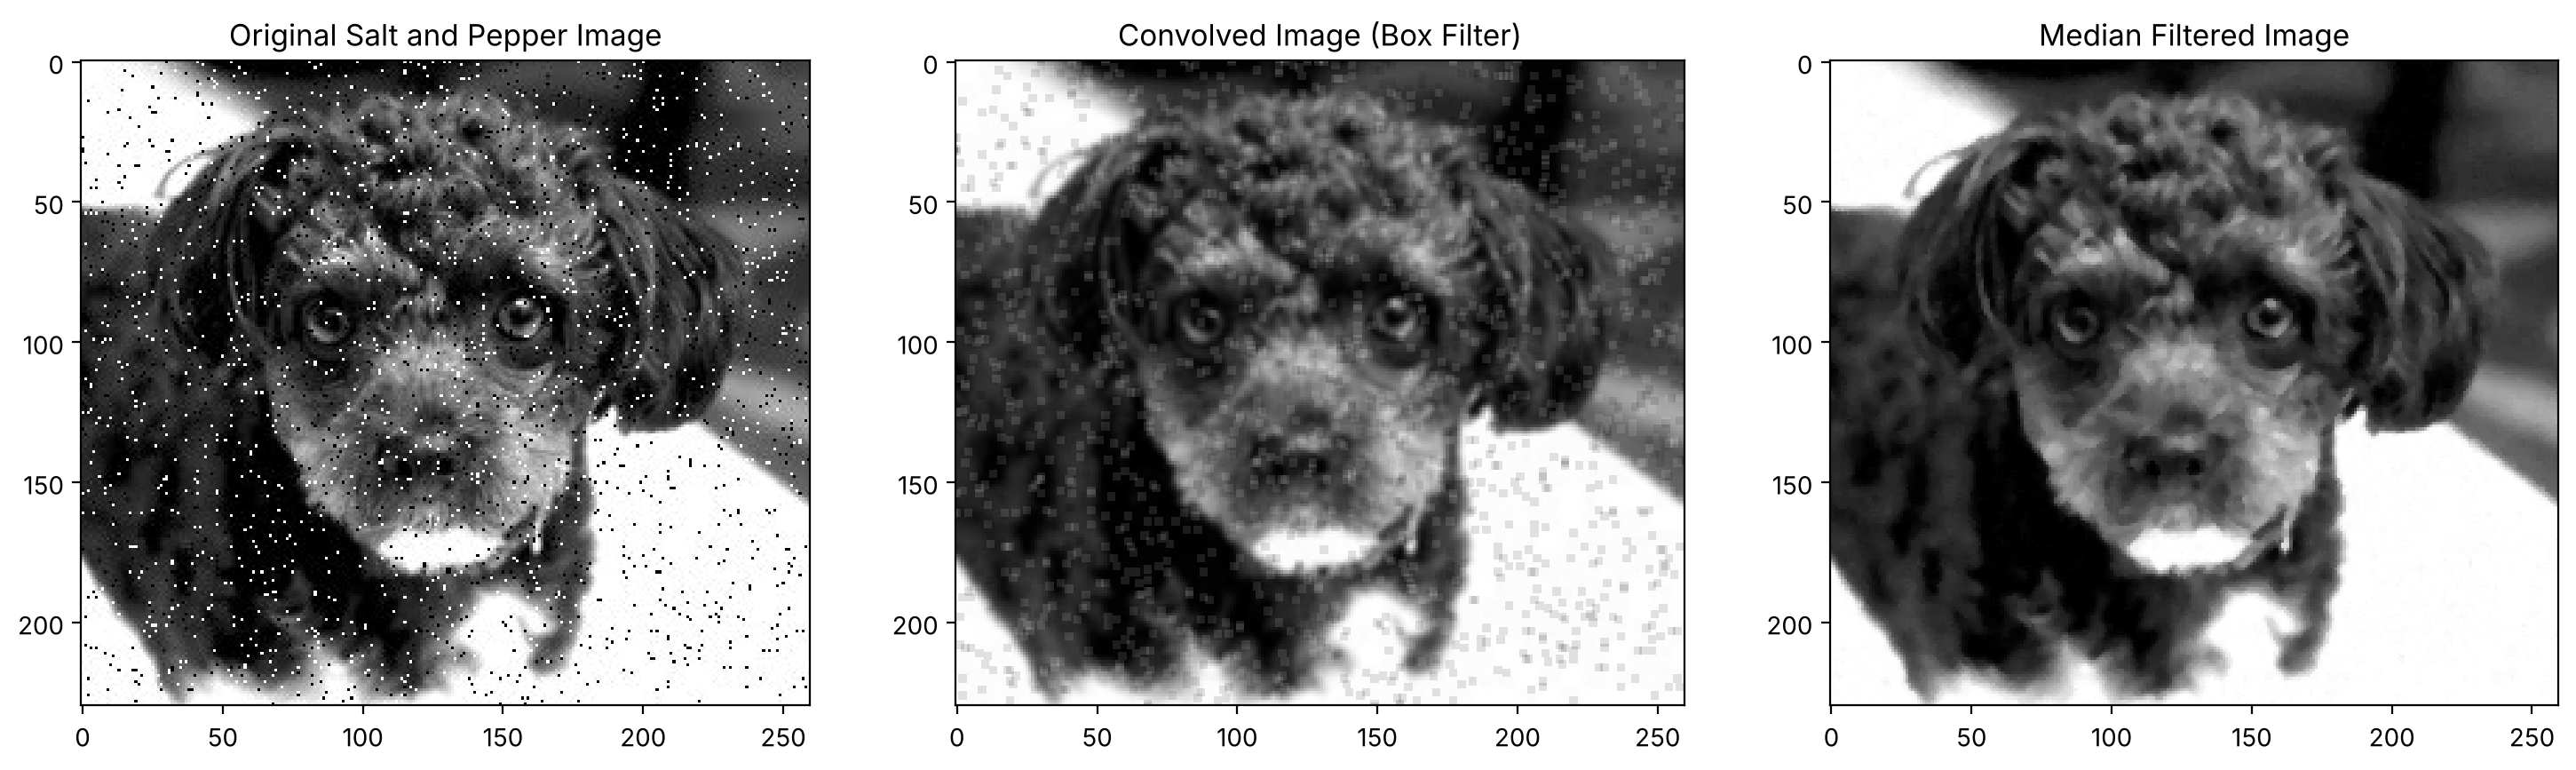

In [4]:
convolved_image = apply_conv2d_box(salt_and_pepper_array)
median_filtered_image = apply_median_filter(salt_and_pepper_array)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(salt_and_pepper_array, cmap='gray')
ax[0].set_title('Original Salt and Pepper Image')
ax[1].imshow(convolved_image, cmap='gray')
ax[1].set_title('Convolved Image (Box Filter)')
ax[2].imshow(median_filtered_image, cmap='gray')
ax[2].set_title('Median Filtered Image')
plt.show()

## Teilaufgabe 2: Automatische Schwellenwertfindung (Thresholding)

Nachdem wir im ersten Schritt das Rauschen im Bild reduziert haben, ist der nächste typische Schritt der Bildanalyse die **Segmentierung**. Das Ziel ist es, das Bild in sinnvolle Bereiche zu unterteilen. Die grundlegendste Form der Segmentierung ist die **Binarisierung**: Wir teilen das Bild in genau zwei Klassen auf: **Vordergrund** (Objekte von Interesse) und **Hintergrund**.

Dies geschieht durch Anwenden eines **Schwellenwerts (Thresholds)** $T$. Jedes Pixel $I(i, j)$ wird überprüft:
* Ist $I(i, j) > T$, wird es dem Vordergrund (z.B. Weiß, Wert 255) zugeordnet.
* Ist $I(i, j) \leq T$, wird es dem Hintergrund (z.B. Schwarz, Wert 0) zugeordnet.

Die zentrale Herausforderung ist: Wie findet man den **optimalen Schwellenwert** $T$ automatisch? Ein manuell gewählter Wert funktioniert vielleicht für ein Bild, aber scheitert bei unterschiedlichen Lichtverhältnissen.

In dieser Aufgabe werden wir zwei fundamentale Algorithmen implementieren, um $T$ automatisch aus den Bilddaten (dem Histogramm) abzuleiten.

### Vorbereitung: Das Histogramm

Beide Methoden basieren nicht auf dem Bild selbst, sondern auf dessen **Histogramm**. Das Histogramm $h(g)$ zählt, wie oft jeder Grauwert $g$ (von 0 bis 255) im Bild vorkommt. Bevor Sie die Algorithmen implementieren, werden Sie eine Funktion zur Berechnung des Histogramms eines Bildes erstellen.

### 1. Der iterative Algorithmus

Dieser Ansatz ist ein intuitives, schrittweises Verfahren, um sich einem stabilen Schwellenwert anzunähern.

Der Algorithmus funktioniert (vereinfacht) wie folgt:
1.  **Starte** mit einer ersten Schätzung für $T$ (z.B. dem mittleren Grauwert des gesamten Bildes).
2.  **Segmentiere** das Bild mit diesem $T$ in zwei Gruppen: $G_1$ (Pixel $\leq T$) und $G_2$ (Pixel $> T$).
3.  **Berechne** den mittleren Grauwert $\mu_1$ von $G_1$ und den mittleren Grauwert $\mu_2$ von $G_2$.
4.  **Setze** einen neuen Schwellenwert $T_{\text{neu}} = \frac{\mu_1 + \mu_2}{2}$.
5.  **Wiederhole** die Schritte 2-4, bis sich $T$ nicht mehr oder nur noch minimal ändert (Konvergenz).

### 2. Die Methode von Otsu

Die **Methode von Otsu** ist ein "intelligenterer" und sehr weit verbreiteter statistischer Ansatz. Otsus Methode analysiert das **Histogramm**, um die **optimale Trennung** zwischen Vorder- und Hintergrund zu finden.

Die Kernidee ist: Der Algorithmus testet jeden möglichen Grauwert $T$ (von 0 bis 255) als potenziellen Schwellenwert. Um dies effizient zu tun, nutzt der Algorithmus **kumulative Summen** (oft als kumulatives Histogramm bezeichnet), die Sie ebenfalls berechnen werden:

1.  **Normalisiertes Histogramm (Wahrscheinlichkeiten)** $p(g)$: Der Anteil jedes Grauwerts an der Gesamtpixelzahl.
2.  **Kumulative Summe (Anteil)** $w(T) = \sum_{g=0}^{T} p(g)$: Der prozentuale Anteil der Pixel, die zur Klasse 1 (Hintergrund) gehören, wenn bei $T$ getrennt wird.
3.  **Kumulative Summe (Mittelwerte)** $\mu(T) = \sum_{g=0}^{T} g \cdot p(g)$: Die Summe der Grauwerte (gewichtet mit ihrer Wahrscheinlichkeit) bis zum Schwellenwert $T$.

Mit diesen Hilfsgrößen testet der Algorithmus jeden Schwellenwert $T$ und berechnet die **Inter-Klassen-Varianz** $\sigma^2_b(T)$ (also den "Abstand" zwischen den beiden Klassen). Die Formel vereinfacht sich durch die kumulativen Summen drastisch:

$$\sigma^2_b(T) = \frac{[\mu_{\text{total}} \cdot w(T) - \mu(T)]^2}{w(T) \cdot (1 - w(T))}$$

* $\mu_{\text{total}}$ ist der mittlere Grauwert des gesamten Bildes.
* $w(T)$ ist der Pixelanteil der Hintergrundklasse (aus der kumulativen Summe 2).
* $\mu(T)$ ist der gewichtete Mittelwert der Hintergrundklasse (aus der kumulativen Summe 3).

Das Ziel ist, denjenigen Schwellenwert $T$ zu finden, der diesen Wert $\sigma^2_b(T)$ **maximiert**. Dieser $T$ gilt als der beste Schwellenwert, um Vorder- und Hintergrund statistisch zu trennen.

---

Ihre Aufgabe ist es, zunächst das Histogramm und die kumulativen Summen zu berechnen und anschließend beide Thresholding-Methoden zu implementieren. Vergleichen Sie die Ergebnisse der beiden Verfahren.


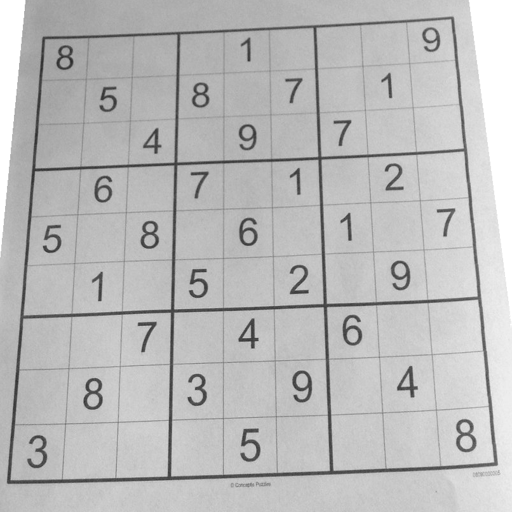

In [5]:
sudoku = Image.open("sudoku.png").convert("L").resize((512, 512))
sudoku_array = np.array(sudoku)
sudoku

In [6]:
from numpy import histogram


def calculate_histogram(img_array: np.ndarray, is_normalized: bool = False) -> np.ndarray:
    """Calculate histogram of the image array.

    Hints:
        - Use img_array.flatten() to iterate over all pixel values in a flattened manner.

    Args:
        img_array (np.ndarray): Input image array.
        is_normalized (bool): Whether to return normalized histogram.
    """
    hist = np.zeros(256, dtype=int)

    for pixel in img_array.flatten():
        hist[pixel] += 1

    if is_normalized:
        return hist.astype(float) / hist.sum()

    return hist

def calculate_cumulative_histogram(histogram: np.ndarray) -> np.ndarray:
    """Calculate cumulative histogram from histogram.

    Hints:
        - Initialize cumulative histogram with zeros using np.zeros_like.
        - Use a for loop to accumulate histogram values.
        - cumulative[i] = cumulative[i - 1] + histogram[i]
        - The first value is simply cumulative[0] = histogram[0]

    Args:
        histogram (np.ndarray): Input histogram.

    Returns:
        np.ndarray: Cumulative histogram.

    """
    cumulative = np.zeros_like(histogram)

    cumulative[0] = histogram[0]
    for i in range(1, len(histogram)):
        cumulative[i] = cumulative[i-1] + histogram[i]

    return cumulative

def find_threshold_iterative(cumulative_histogram: np.ndarray, max_iterations=20) -> int:
    """Iteratively find optimal threshold for image segmentation.

    Hints:
        - Start with an initial threshold T as the mean of the cumulative histogram (np.mean).
        - In each iteration, segment the histogram into two groups based on the current threshold T.
        - Calculate the means of both groups (mu1 and mu2).
        - Update the threshold T_new as the average of mu1 and mu2.
        - Check for convergence: if the change in threshold is less than a small value (e.g., 0.5), break the loop.
        - Return the final threshold scaled to the range [0, 255].

    Args:
        histogram (np.ndarray): Histogram of the image.
        max_iterations (int): Maximum number of iterations to perform.

    Returns:
        int: Optimal threshold value.
    """
    normalized_hist = np.zeros(256)
    normalized_hist[0] = cumulative_histogram[0]
    for i in range(1, 256):
        normalized_hist[i] = cumulative_histogram[i] - cumulative_histogram[i-1]

    gray_values = np.arange(256)

    T = int(np.mean(cumulative_histogram) * 255)

    for _ in range(max_iterations):
        w1 = cumulative_histogram[T]
        w2 = 1.0 - w1

        if w1 > 0:
            mu1 = np.sum(gray_values[:T+1] * normalized_hist[:T+1]) / w1
        else:
            mu1 = 0.0

        if w2 > 0:
            mu2 = np.sum(gray_values[T+1:] * normalized_hist[T+1:]) / w2
        else:
            mu2 = 255.0

        T_new = int((mu1 + mu2) / 2)

        if abs(T_new - T) < 0.5:
            break
        T = T_new

    return T


def find_threshold_by_otsu(normalized_histogram: np.ndarray, cumulative_histogram: np.ndarray) -> int:
    """Find optimal threshold using Otsu's method.

    Hints:
        - Initialize an array to hold variance values for each threshold.
        - Loop through all possible threshold values (0 to 255).
        - For each threshold T, calculate the probabilities P_0 and P_1, taking into account the cumulative histogram.
        - Calculate the means mu_0 and mu_1 for the two classes.
        - Compute the between-class variance using the formula: variance = P_0 * P_1 * (mu_0 - mu_1) ** 2
        - Store the variance for each threshold.
        - Return the threshold that maximizes the between-class variance (np.argmax).

    Args:
        normalized_histogram (np.ndarray): Normalized histogram of the image.
        cumulative_histogram (np.ndarray): Cumulative histogram of the image.

    Returns:
        int: Optimal threshold value.

    """
    variances = np.zeros(256)
    gray_values = np.arange(256)

    weighted_cumulative = np.zeros(256)
    weighted_cumulative[0] = 0 * normalized_histogram[0]
    for i in range(1, 256):
        weighted_cumulative[i] = weighted_cumulative[i-1] + i * normalized_histogram[i]

    mu_total = weighted_cumulative[-1]

    for T in range(256):
        P_0 = cumulative_histogram[T]
        P_1 = 1.0 - P_0

        if P_0 == 0 or P_1 == 0:
            continue

        mu_0 = weighted_cumulative[T] / P_0
        mu_1 = (mu_total - weighted_cumulative[T]) / P_1

        variances[T] = P_0 * P_1 * (mu_0 - mu_1) ** 2

    return int(np.argmax(variances))

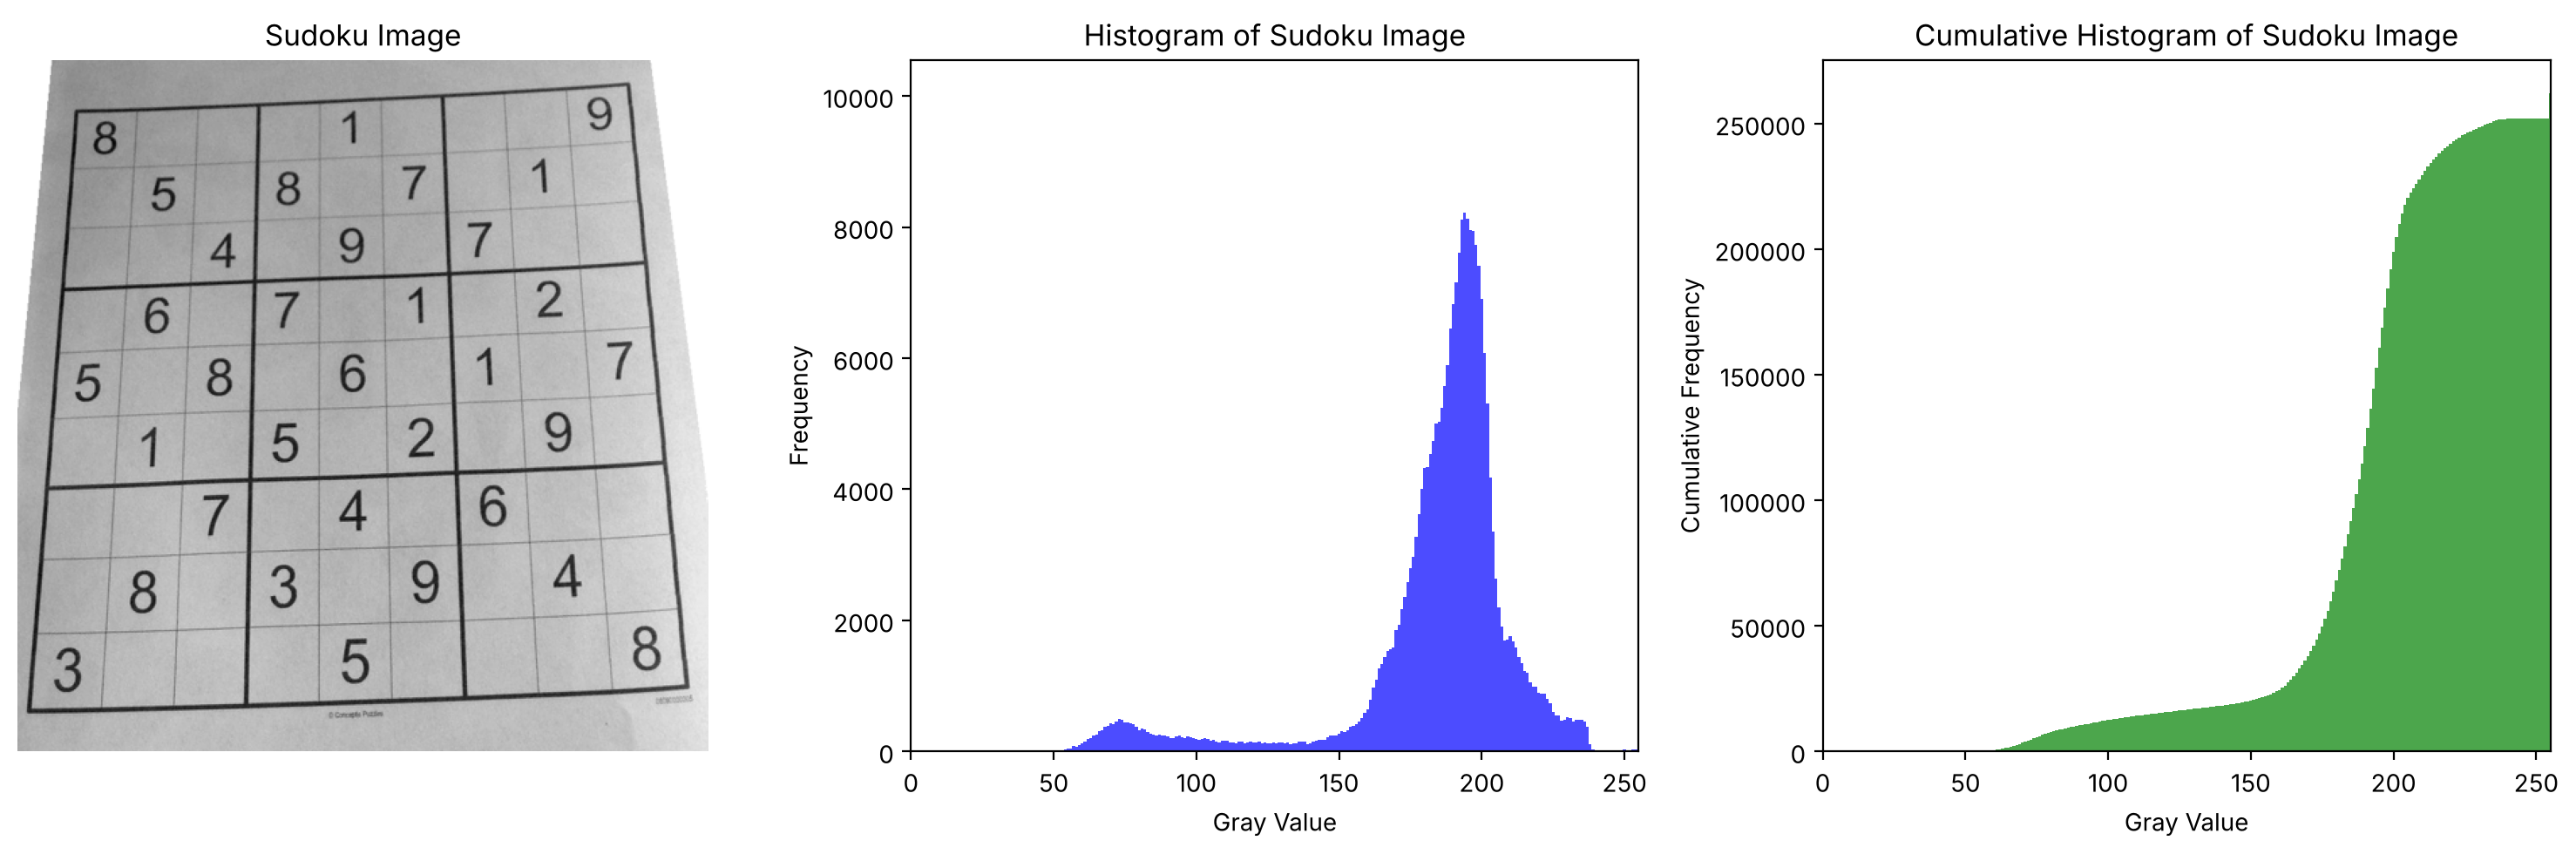

In [7]:
histogram = calculate_histogram(sudoku_array)
cumulative_histogram = calculate_cumulative_histogram(histogram)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(sudoku_array, cmap='gray')
ax[0].set_title('Sudoku Image')
ax[0].axis('off')

ax[1].bar(range(256), histogram, width=1.0, color='blue', alpha=0.7)
ax[1].set_xlabel('Gray Value')
ax[1].set_ylabel('Frequency')
ax[1].set_title('Histogram of Sudoku Image')
ax[1].set_xlim(0, 255)

ax[2].bar(range(256), cumulative_histogram, width=1.0, color='green', alpha=0.7)
ax[2].set_xlabel('Gray Value')
ax[2].set_ylabel('Cumulative Frequency')
ax[2].set_title('Cumulative Histogram of Sudoku Image')
ax[2].set_xlim(0, 255)

plt.tight_layout()
plt.show()

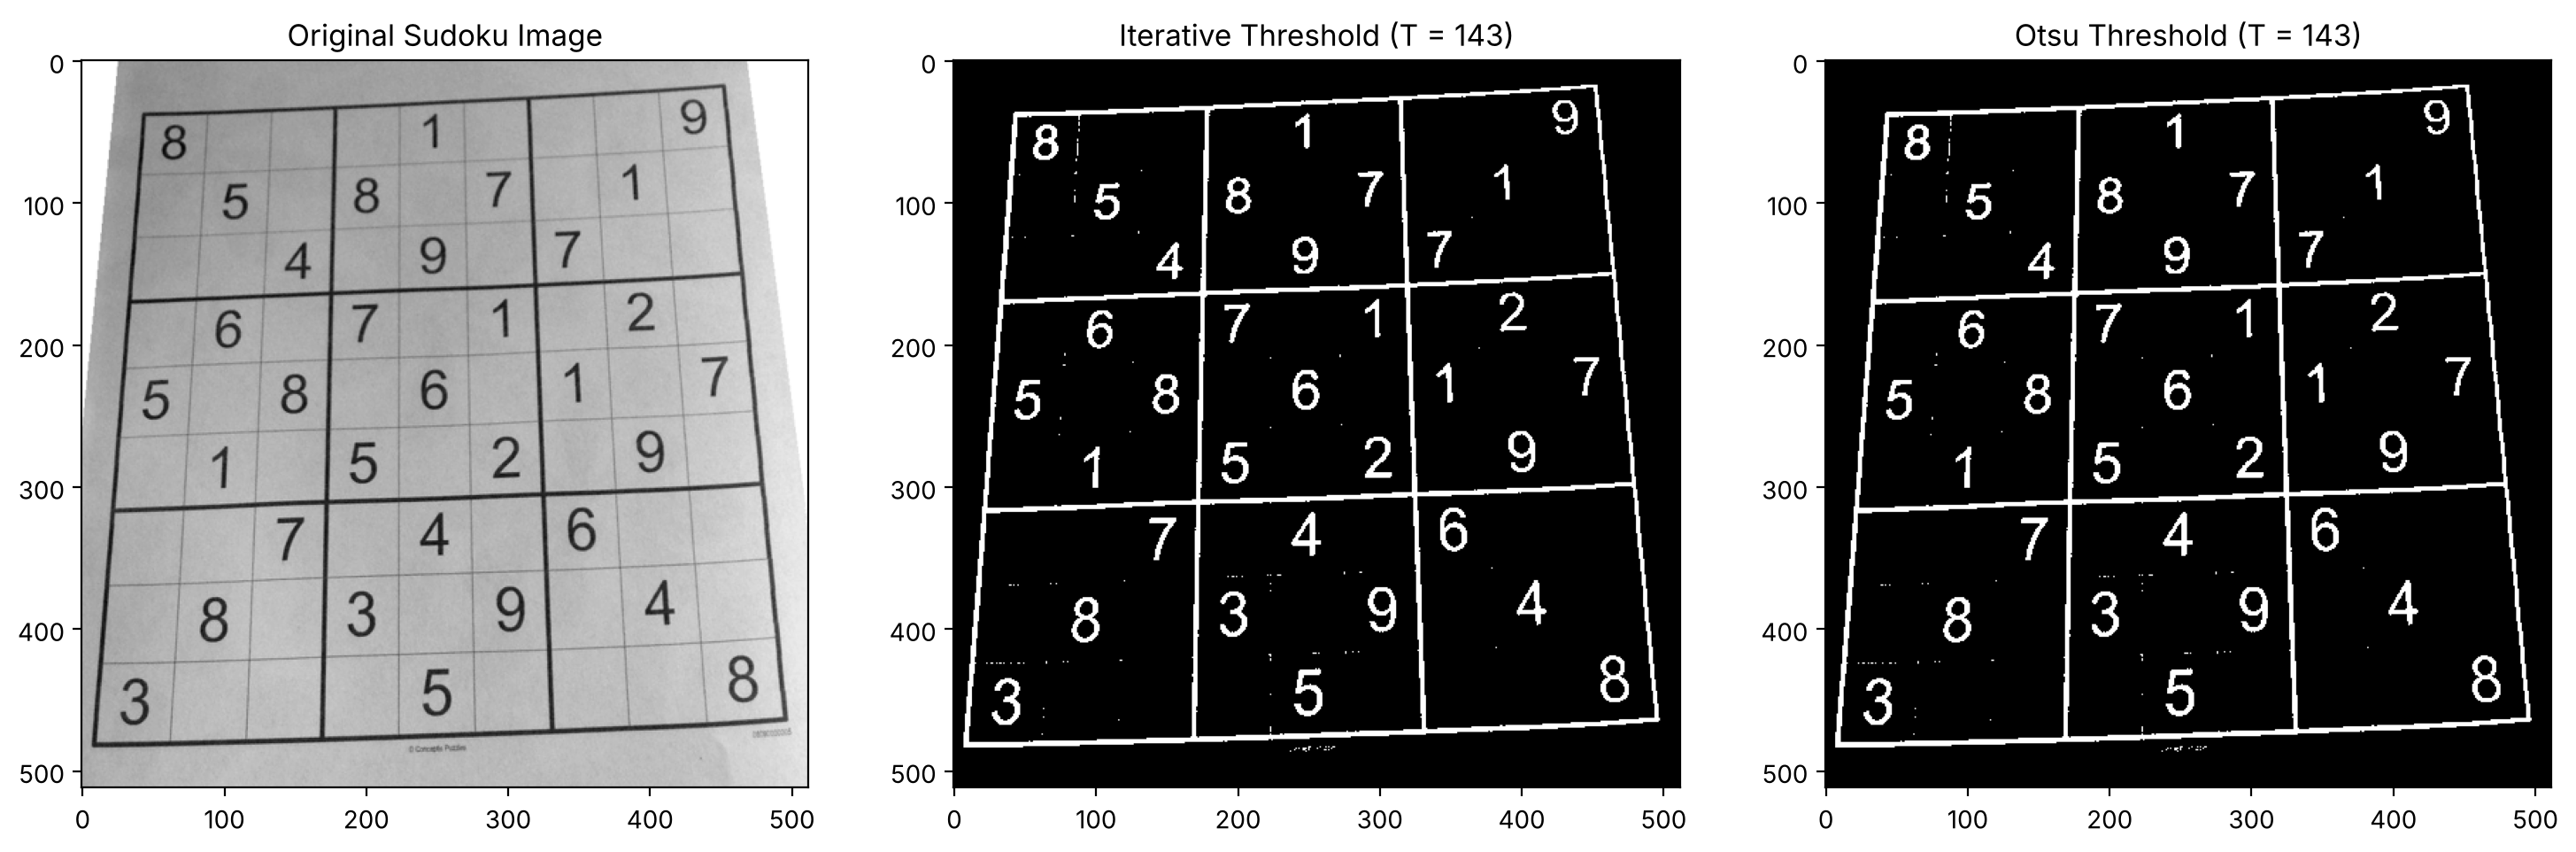

In [8]:
normalized_histogram = calculate_histogram(sudoku_array, is_normalized=True)
normalized_cumulative_histogram = calculate_cumulative_histogram(normalized_histogram)

iterative_threshold = find_threshold_iterative(normalized_cumulative_histogram)
otsu_threshold = find_threshold_by_otsu(normalized_histogram, normalized_cumulative_histogram)

iterative_segmented = (sudoku_array <= iterative_threshold).astype(np.uint8) * 255
otsu_segmented = (sudoku_array <= otsu_threshold).astype(np.uint8) * 255

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(sudoku_array, cmap='gray')
ax[0].set_title('Original Sudoku Image')
ax[1].imshow(iterative_segmented, cmap='gray')
ax[1].set_title(f'Iterative Threshold (T = {iterative_threshold})')
ax[2].imshow(otsu_segmented, cmap='gray')
ax[2].set_title(f'Otsu Threshold (T = {otsu_threshold})')
plt.show()

## Teilaufgabe 3: Morphologische Operatoren

Nachdem wir in Teil 2 gelernt haben, wie man ein Graustufenbild in ein **Binärbild** (Schwarz-Weiß) umwandelt, ist der nächste Schritt oft die "Bereinigung" dieses Bildes. Das Ergebnis einer Schwellenwertbildung ist selten perfekt: Es kann kleine, isolierte "Rauschpixel" (sowohl schwarze Löcher im Vordergrund als auch weiße Flecken im Hintergrund) oder dünne "Brücken", die Objekte fälschlicherweise verbinden, enthalten.

Hier kommen **morphologische Operatoren** ins Spiel. Dies sind nicht-lineare Operationen, die auf der **Form** (oder Morphologie) von Objekten in einem Bild arbeiten. Sie werden verwendet, um die Struktur von Binärbildern zu analysieren und zu modifizieren.

### Das Strukturelement (SE)

Alle morphologischen Operationen basieren auf einem **Strukturelement (SE)**. Dies ist ein kleiner "Kernel" (ähnlich wie unser Faltungskern), der als "Sonde" über das Bild geschoben wird. Für unsere Aufgabe verwenden wir ein einfaches 3x3-Quadrat als SE:

$$SE = \begin{pmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{pmatrix}$$

### Die Grundoperationen: Erosion und Dilatation

Die beiden fundamentalen Operationen, aus denen fast alle anderen abgeleitet werden, sind Erosion und Dilatation.

1.  **Erosion (Schrumpfen)**:
    Die Erosion *verkleinert* die Grenzen von Vordergrundobjekten (weiße Bereiche). Ein Pixel im Ausgabebild wird *nur dann* auf Weiß (1) gesetzt, wenn das **gesamte** Strukturelement, zentriert auf diesem Pixel, **vollständig** auf Vordergrundpixel im Eingabebild passt.
    * **Effekt**: Dünne Linien und isolierte weiße Pixel (Rauschen) werden komplett entfernt. Objekte schrumpfen.

2.  **Dilatation (Wachsen)**:
    Die Dilatation *vergrößert* die Grenzen von Vordergrundobjekten. Ein Pixel im Ausgabebild wird auf Weiß (1) gesetzt, wenn das Strukturelement, zentriert auf diesem Pixel, **mindestens ein** Vordergrundpixel im Eingabebild "trifft" (überlappt).
    * **Effekt**: Kleine schwarze Löcher in Objekten werden gefüllt. Objekte wachsen und können miteinander verschmelzen.

### Unsere Ziel-Operation: Die Öffnung (Opening)

In dieser Aufgabe implementieren wir die **Öffnung (Opening)**. Diese Operation ist definiert als eine **Erosion, *gefolgt* von einer Dilatation** (mit demselben Strukturelement).

Warum diese Kombination?
1.  Die **Erosion** entfernt zunächst alle kleinen Rauschpixel (wie in Teil 1 das "Salz"-Rauschen, nur jetzt im Binärbild) und bricht dünne Brücken zwischen Objekten auf. Größere Objekte schrumpfen dabei.
2.  Die anschließende **Dilatation** vergrößert die verbliebenen (bereinigten) Objekte wieder auf ungefähr ihre ursprüngliche Größe. Wichtig dabei: Das Rauschen, das im ersten Schritt entfernt wurde, "wächst nicht nach"!

Der Nettoeffekt der Öffnung ist also die **Entfernung kleiner Objekte und die Glättung von Konturen**, ohne die Größe der Hauptobjekte signifikant zu verändern.

---

Ihre Aufgabe ist es, die Operationen **Erosion** und **Dilatation** von Grund auf zu implementieren und diese dann zur **Öffnung** zu kombinieren. Wenden Sie Ihre Implementierung auf die Binärbilder aus Teil 2 an und beobachten Sie den Bereinigungseffekt.

In [9]:
def apply_binary_erosion(img: np.ndarray, structuring_element: np.ndarray) -> np.ndarray:
    """Apply binary erosion to the binary image using the given structuring element.


    Hint:
        - For each pixel in the image, check if the structuring element fits entirely within the foreground (1s) of the image.
        - Use nested loops to iterate over each pixel and the structuring element.
        - If all pixels under the structuring element are 1s, set the output pixel to 1; otherwise, set it to 0.
        - Any pixel outside the image boundaries should be considered as 0.

    Args:
        img (np.ndarray): Input binary image as a 2D numpy array.
        structuring_element (np.ndarray): Structuring element as a 2D numpy array.

    Returns:
        np.ndarray: Eroded binary image as a 2D numpy array.
    """
    if structuring_element.shape[0] != 3 or structuring_element.shape[1] != 3:
        raise ValueError("Structuring element must be of size 3x3.")

    eroded_img = np.zeros_like(img)
    se_range = range(-1, 2)
    height, width = img.shape

    for i in range(height):
        for j in range(width):
            fits = True
            for u in se_range:
                for v in se_range:
                    if structuring_element[u+1, v+1] == 0:
                        continue
                    ni, nj = i + u, j + v
                    if ni < 0 or ni >= height or nj < 0 or nj >= width:
                        fits = False
                        break
                    if not img[ni, nj]:
                        fits = False
                        break
                if not fits:
                    break
            if fits:
                eroded_img[i, j] = 1

    return eroded_img

def apply_binary_dilation(img: np.ndarray, structuring_element: np.ndarray) -> np.ndarray:
    """Apply binary dilation to the binary image using the given structuring element.

    Hint:
        - For each pixel in the image, check if the structuring element overlaps with any foreground (1s) of the image.
        - Use nested loops to iterate over each pixel and the structuring element.
        - If any pixel under the structuring element is a 1, set the output pixel to 1; otherwise, set it to 0.
        - Any pixel outside the image boundaries should be considered as 0.

    Args:
        img (np.ndarray): Input binary image as a 2D numpy array.
        structuring_element (np.ndarray): Structuring element as a 2D numpy array.

    Returns:
        np.ndarray: Dilated binary image as a 2D numpy array.
    """
    if structuring_element.shape[0] != 3 or structuring_element.shape[1] != 3:
        raise ValueError("Structuring element must be of size 3x3.")

    dilated_img = np.zeros_like(img)
    se_range = range(-1, 2)
    height, width = img.shape

    for i in range(height):
        for j in range(width):
            for u in se_range:
                for v in se_range:
                    if structuring_element[u+1, v+1] == 0:
                        continue
                    ni, nj = i + u, j + v
                    if ni < 0 or ni >= height or nj < 0 or nj >= width:
                        continue
                    if img[ni, nj]:
                        dilated_img[i, j] = 1
                        break
                else:
                    continue
                break

    return dilated_img

def apply_binary_opening(img: np.ndarray, structuring_element: np.ndarray) -> np.ndarray:
    """Apply binary opening to the binary image using the given structuring element.

    Hint:
        - Apply erosion followed by dilation using the same structuring element.
        - This will remove small objects from the foreground and smooth the boundaries.

    Args:
        img (np.ndarray): Input binary image as a 2D numpy array.
        structuring_element (np.ndarray): Structuring element as a 2D numpy array.

    Returns:
        np.ndarray: Opened binary image as a 2D numpy array.
    """
    eroded = apply_binary_erosion(img, structuring_element)
    return apply_binary_dilation(eroded, structuring_element)

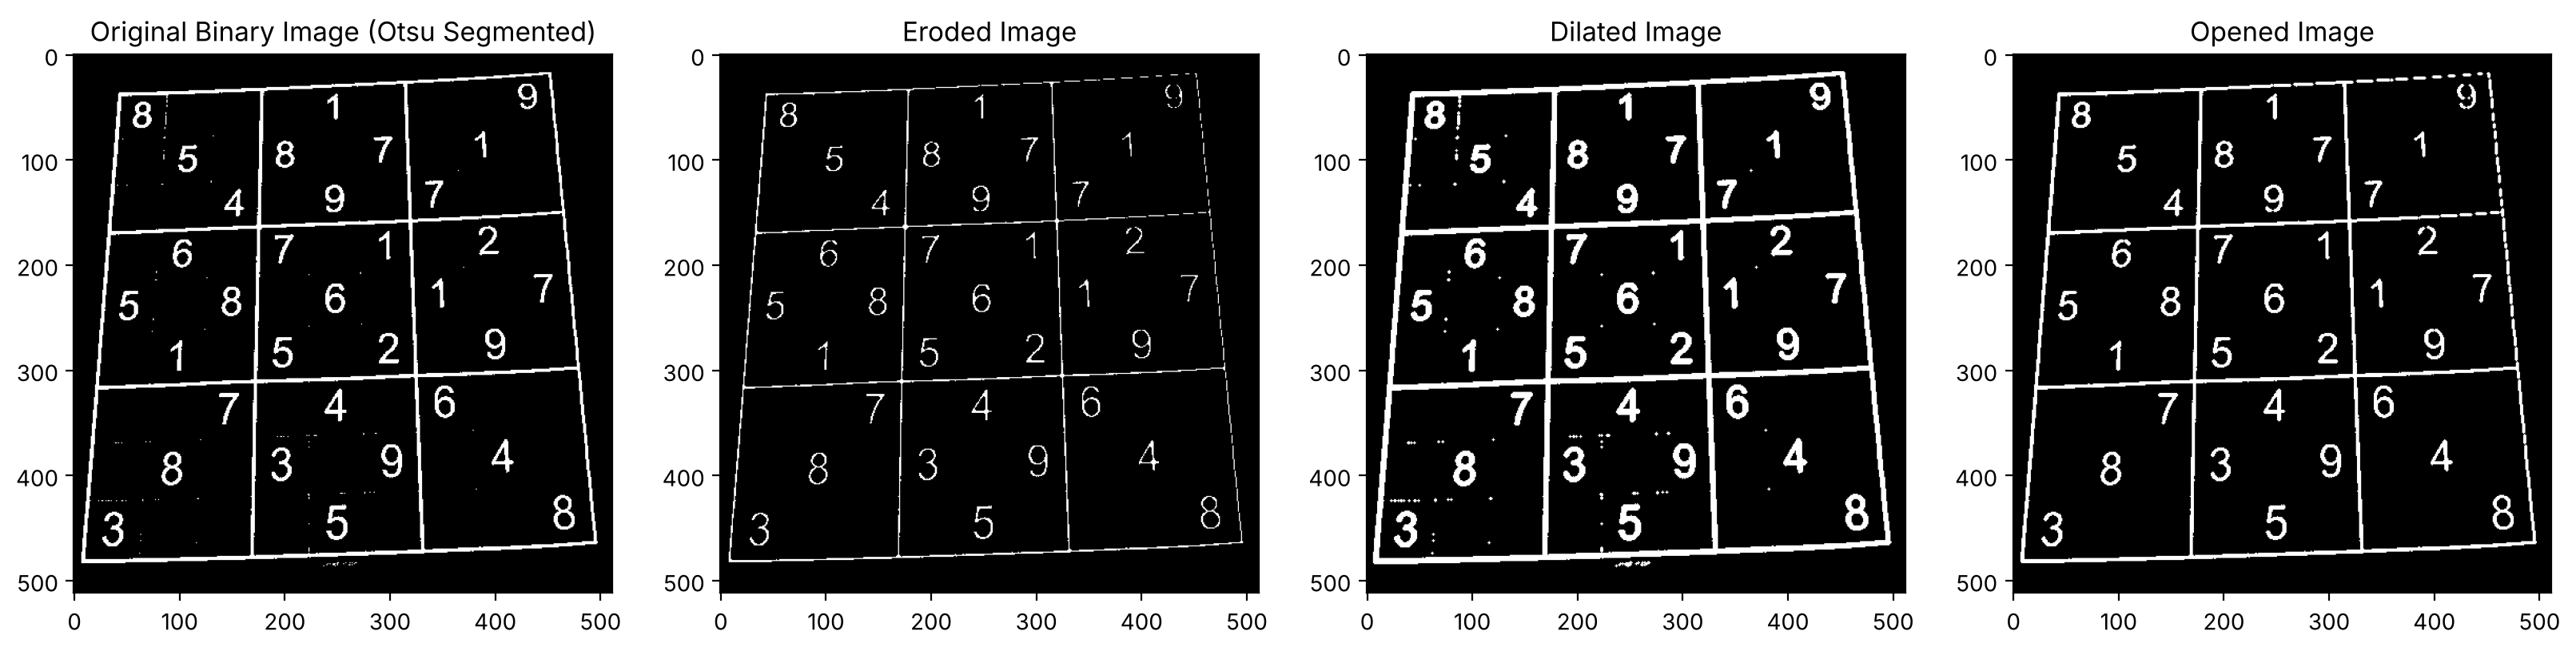

In [10]:
otsu_segmented = (sudoku_array <= otsu_threshold).astype(np.bool)

kernel = np.array([[0, 1, 0],
                   [1, 1, 1],
                   [0, 1, 0]], dtype=np.uint8)


eroded_img = apply_binary_erosion(otsu_segmented, structuring_element=kernel)
dilated_img = apply_binary_dilation(otsu_segmented, structuring_element=kernel)
opened_img = apply_binary_opening(otsu_segmented, structuring_element=kernel)

fig, ax = plt.subplots(1, 4, figsize=(20, 6))
ax[0].imshow(otsu_segmented, cmap='gray')
ax[0].set_title('Original Binary Image (Otsu Segmented)')
ax[1].imshow(eroded_img, cmap='gray')
ax[1].set_title('Eroded Image')
ax[2].imshow(dilated_img, cmap='gray')
ax[2].set_title('Dilated Image')
ax[3].imshow(opened_img, cmap='gray')
ax[3].set_title('Opened Image')
plt.show()


## Teilaufgabe 4: Die Hough-Transformation zur Linienerkennung

Nachdem wir unser Bild gefiltert (Teil 1), binarisiert (Teil 2) und morphologisch bereinigt (Teil 3) haben, besitzen wir nun eine saubere Darstellung der Bildobjekte. Der nächste logische Schritt in vielen Bildverarbeitungs-Pipelines ist die **Merkmalsextraktion**: Wir wollen die Objekte nicht nur *sehen*, sondern sie auch *beschreiben* oder *finden*.

In dieser letzten Aufgabe implementieren wir die **Hough-Transformation**, eine fundamentale und leistungsstarke Technik, um geometrische Grundformen – in unserem Fall **Linien** – in einem Bild zu detektieren.

### Die Herausforderung

Das Finden von Linien in einem Bild ist nicht trivial. Eine Linie kann lückenhaft sein (gestrichelt), teilweise verdeckt oder durch Rauschen gestört sein. Ein Algorithmus, der einfach versucht, benachbarte Pixel zu verbinden, würde hier schnell scheitern.

### Die Kernidee: Vom Bildraum zum Parameterraum

Die Hough-Transformation löst dieses Problem durch einen cleveren "Trick": Sie verwendet ein **Abstimmungsverfahren (Voting)**. Statt im Bildraum (x, y) nach Linien zu suchen, wandelt sie jeden Punkt in einen "Parameterraum" um und lässt die Punkte dort für alle Linien "abstimmen", zu denen sie gehören *könnten*.

Für die Linienerkennung verwenden wir die **Hessesche Normalform** zur Darstellung einer Linie:

$$\rho = x \cdot \cos(\theta) + y \cdot \sin(\theta)$$

* $(x, y)$ sind die Koordinaten eines Pixels im Bild.
* $\rho$ (rho) ist der senkrechte Abstand der Linie vom Ursprung (0, 0).
* $\theta$ (theta) ist der Winkel der Normalen (der Senkrechten) dieser Linie zur x-Achse.



**Der Clou:**
1.  Ein einzelner Punkt $(x, y)$ im Bildraum entspricht einer **Sinuskurve** im $(\rho, \theta)$-Parameterraum (dem "Hough-Raum"), denn für ein festes $(x, y)$ gibt es unendlich viele Linien (unendlich viele Paare von $\rho$ und $\theta$), die durch diesen Punkt gehen.
2.  Liegen mehrere Punkte $(x_1, y_1), (x_2, y_2), ...$ im Bildraum auf derselben Linie (z.B. mit den Parametern $\rho_{\text{linie}}$ und $\theta_{\text{linie}}$), **schneiden sich ihre jeweiligen Sinuskurven** im Hough-Raum alle in *genau einem Punkt*: $(\rho_{\text{linie}}, \theta_{\text{linie}})$.

### Der Akkumulator

Ihre Aufgabe ist es, diesen Abstimmungsprozess zu implementieren:
1.  Sie erstellen eine 2D-Matrix, den sogenannten **Akkumulator**. Dieses 2D-Histogramm repräsentiert den diskretisierten $(\rho, \theta)$-Raum (z.B. $\theta$ von $0^\circ$ bis $180^\circ$ und $\rho$ von $-D$ bis $+D$, wobei $D$ die Bilddiagonale ist).
2.  Sie iterieren über **jedes weiße Pixel** $(x, y)$ in Ihrem **bereinigten Binärbild** (dem Ergebnis der Öffnung aus Teil 3).
3.  Für jedes dieser Pixel berechnen Sie die zugehörige Sinuskurve im Hough-Raum (indem Sie $\theta$ von $0^\circ$ bis $180^\circ$ durchlaufen und das jeweilige $\rho$ berechnen).
4.  Für jeden Punkt $(\rho, \theta)$ auf dieser Kurve **erhöhen Sie den Zähler (Vote)** in der entsprechenden Zelle des Akkumulators.

Am Ende dieses Vorgangs entsprechen die Zellen im Akkumulator mit den **höchsten Werten (Peaks)** den dominantesten Linien im Bild. Die Koordinaten $(\rho, \theta)$ dieser Peaks sind die Parameter der gefundenen Linien.

**Warum das Bild aus Teil 3?** Wir verwenden das Ergebnis der morphologischen Öffnung, da es Rauschpixel entfernt hat. Jedes Rauschpixel würde fälschlicherweise für hunderte von Linien "stimmen" und den Akkumulator "verschmutzen". Durch die saubere Eingabe wird unsere Linienerkennung wesentlich robuster und genauer.

In [11]:
def apply_hough_transform(binary_image:np.ndarray, top_k:int=5) -> tuple[list[tuple[int, int]], np.ndarray]:
    """Apply Hough Transform to detect lines in the image.


    Hints:
        - Initialize the Hough accumulator array with zeros. The shape should be (2 * max_acc, max_angle_deg).
        - Loop through each pixel in the binary image. If the pixel is an edge (255), loop through all possible theta values (0 to 180 degrees).
        - For each theta, calculate rho using the formula: rho = x * cos(theta) + y * sin(theta).
        - Increment the corresponding cell in the Hough accumulator.
        - After populating the Hough accumulator, find the top_k lines by locating the highest values in the accumulator (np.argmax).
        - Return the list of detected lines in (rho, theta) format and the Hough accumulator array.
        - np.deg2rad can be used to convert degrees to radians.
        - np.cos and np.sin can be used to compute cosine and sine values.
        - np.sqrt can be used to compute the square root.
        - np.argmax return a flattened index, use np.unravel_index to convert it the proper, rho, theta coordinates

    Args:
        binary_image (np.ndarray): Binary image array where edges are marked with 255.
        top_k (int): Number of top lines to return based on votes.

    Returns:
        hough_lines (list of tuples): List of detected lines in (rho, theta) format.
        hough_space (np.ndarray): The Hough accumulator array.

    """
    height, width = binary_image.shape
    max_rho = int(np.sqrt(height**2 + width**2))
    max_angle_deg = 180

    accumulator = np.zeros((2 * max_rho, max_angle_deg), dtype=int)

    edge_pixels = np.argwhere(binary_image == 255)
    for y, x in edge_pixels:
        for theta_deg in range(max_angle_deg):
            theta = np.deg2rad(theta_deg)
            rho = int(x * np.cos(theta) + y * np.sin(theta))
            rho_idx = rho + max_rho
            if 0 <= rho_idx < 2 * max_rho:
                accumulator[rho_idx, theta_deg] += 1

    hough_lines = []
    acc_copy = accumulator.copy()

    for _ in range(top_k):
        idx = np.argmax(acc_copy)
        rho_idx, theta_idx = np.unravel_index(idx, acc_copy.shape)
        rho = rho_idx - max_rho
        theta = theta_idx
        hough_lines.append((rho, theta))
        acc_copy[max(0, rho_idx-10):min(2*max_rho, rho_idx+10),
                 max(0, theta_idx-10):min(max_angle_deg, theta_idx+10)] = 0

    return hough_lines, accumulator

In [12]:
def visualize_hough_lines(image_array: np.ndarray, hough_lines: np.ndarray, hough_space: np.ndarray):
    """Visualize detected Hough lines on the image."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

    ax1.imshow(image_array, cmap='gray')

    height, width = image_array.shape

    for rho, theta in hough_lines:
        theta = np.deg2rad(theta)
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))

        ax1.plot([x1, x2], [y1, y2], 'r-', linewidth=2, alpha=0.7)

    ax1.set_xlim(0, width)
    ax1.set_ylim(height, 0)
    ax1.set_title(f'Detected Hough Lines (top {len(hough_lines)})')
    ax2.imshow(hough_space, cmap='hot', aspect='auto')
    ax2.set_xlabel('Theta (degrees)')
    ax2.set_ylabel('Rho')
    ax2.set_title('Hough Space')
    plt.tight_layout()
    plt.show()

In [13]:
normalized_histogram = calculate_histogram(sudoku_array, is_normalized=True)
normalized_cumulative_histogram = calculate_cumulative_histogram(normalized_histogram)

iterative_threshold = find_threshold_iterative(normalized_cumulative_histogram)
binary_img = (sudoku_array <= iterative_threshold).astype(np.uint8) * 255

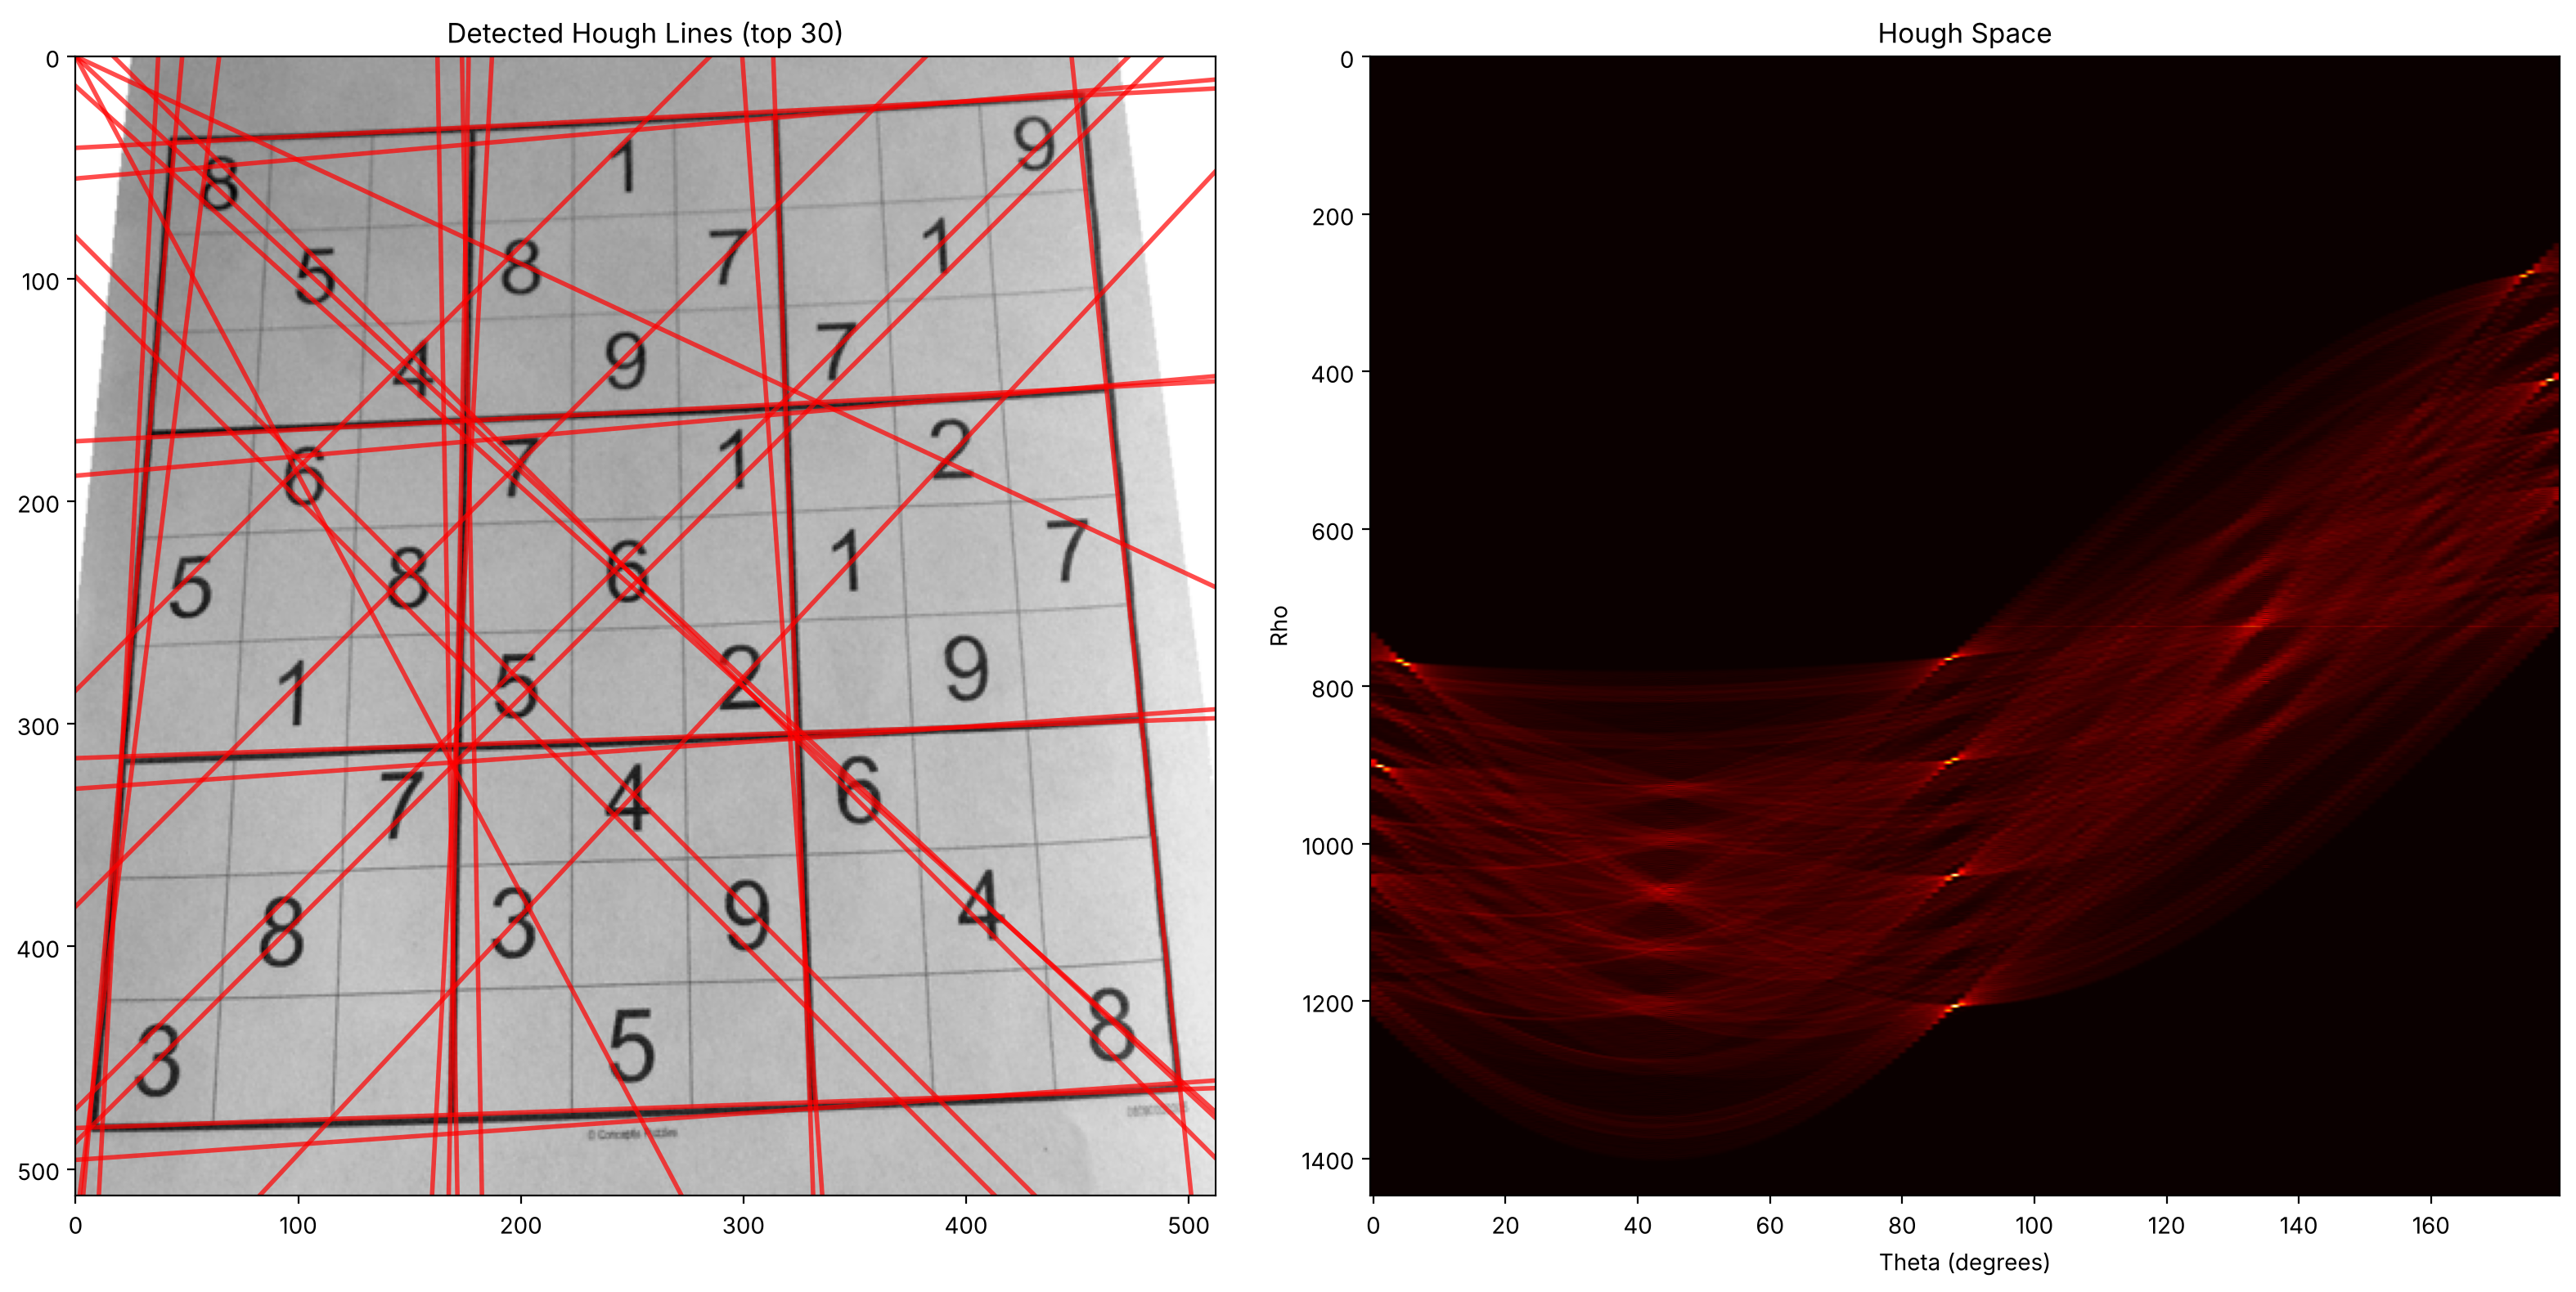

In [14]:
hough_lines, hough_space = apply_hough_transform(binary_img, top_k=30)
visualize_hough_lines(sudoku_array, hough_lines, hough_space)